<a href="https://colab.research.google.com/github/saraxfl/Notebook/blob/main/Collab4_Bloque2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 4. CO₂ mensual en Mauna Loa
 El entrenamiento va de enero de 1975 a diciembre de 2025. Enero a septiembre de 2026 se reserva para revisar el pronóstico.



In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX

url = "https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv"
datos = pd.read_csv(url, comment="#")
datos.index = pd.to_datetime(datos[["year", "month"]].assign(day=1))
datos = datos.sort_index().asfreq("MS")
co2 = datos["average"].where(datos["average"].gt(0))
entrenamiento = co2.loc["1975-01":"2025-12"]
prueba = co2.loc["2026-01":"2026-09"]
if len(entrenamiento) != 612 or entrenamiento.isna().any():
    raise ValueError("Comprueba que NOAA tenga los 612 meses válidos de entrenamiento.")
print(f"{len(entrenamiento)} meses para ajustar · {prueba.notna().sum()} meses observados para evaluar")

612 meses para ajustar · 9 meses observados para evaluar


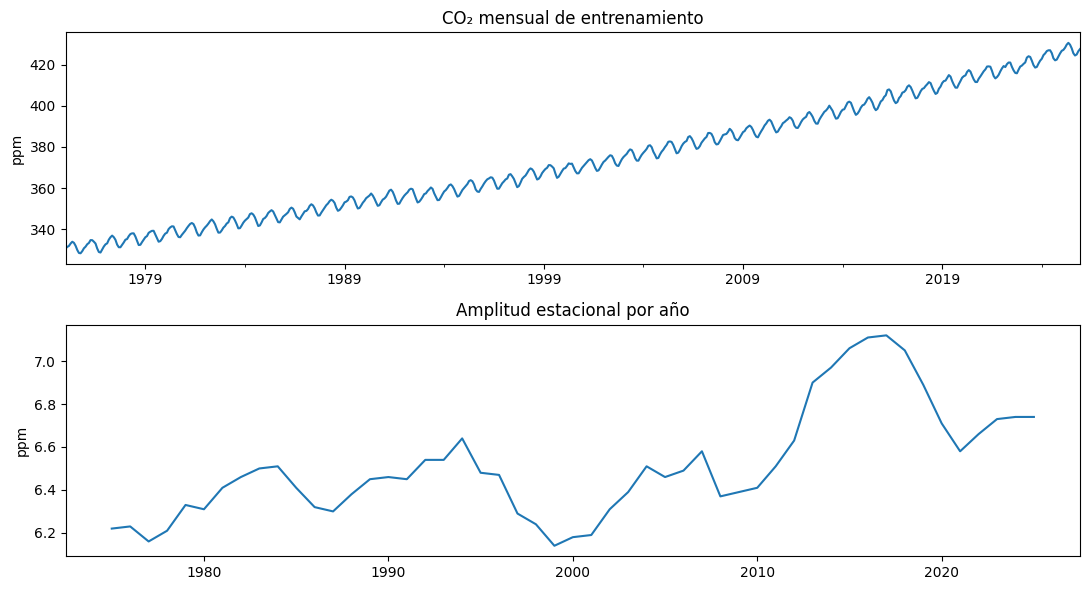

,Nivel medio,Amplitud
1975,331.13,6.22
2025,427.35,6.74


In [7]:
ajustado = datos["deseasonalized"].where(datos["deseasonalized"].gt(0))
ciclo = (co2 - ajustado).loc[entrenamiento.index]
amplitud = ciclo.groupby(ciclo.index.year).agg(lambda valores: valores.max() - valores.min())
nivel = entrenamiento.groupby(entrenamiento.index.year).mean()

fig, ejes = plt.subplots(2, 1, figsize=(11, 6))
entrenamiento.plot(ax=ejes[0], title="CO₂ mensual de entrenamiento", ylabel="ppm")
amplitud.plot(ax=ejes[1], title="Amplitud estacional por año", ylabel="ppm")
fig.tight_layout()
plt.show()

comparacion = pd.DataFrame({"Nivel medio": nivel, "Amplitud": amplitud}).iloc[[0, -1]]
display(comparacion.round(2))

## Diferencias para el ajuste

Trabajo en ppm porque la amplitud del ciclo cambia menos que el nivel medio entre el primer y el último año de entrenamiento. Primero calculo la diferencia mensual y luego la diferencia de 12 meses. Uso ACF y PACF para examinar los rezagos del resultado.

/tmp/ipykernel_6787/4294309628.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print(f"ADF inicial, con constante y tendencia: p = {adfuller(entrenamiento, regression='ct')[1]:.3g}")
/tmp/ipykernel_6787/4294309628.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print(f"ADF después de ambas diferencias: p = {adfuller(serie_diferenciada)[1]:.3g}")


ADF inicial, con constante y tendencia: p = 0.995
ADF después de ambas diferencias: p = 1.91e-17


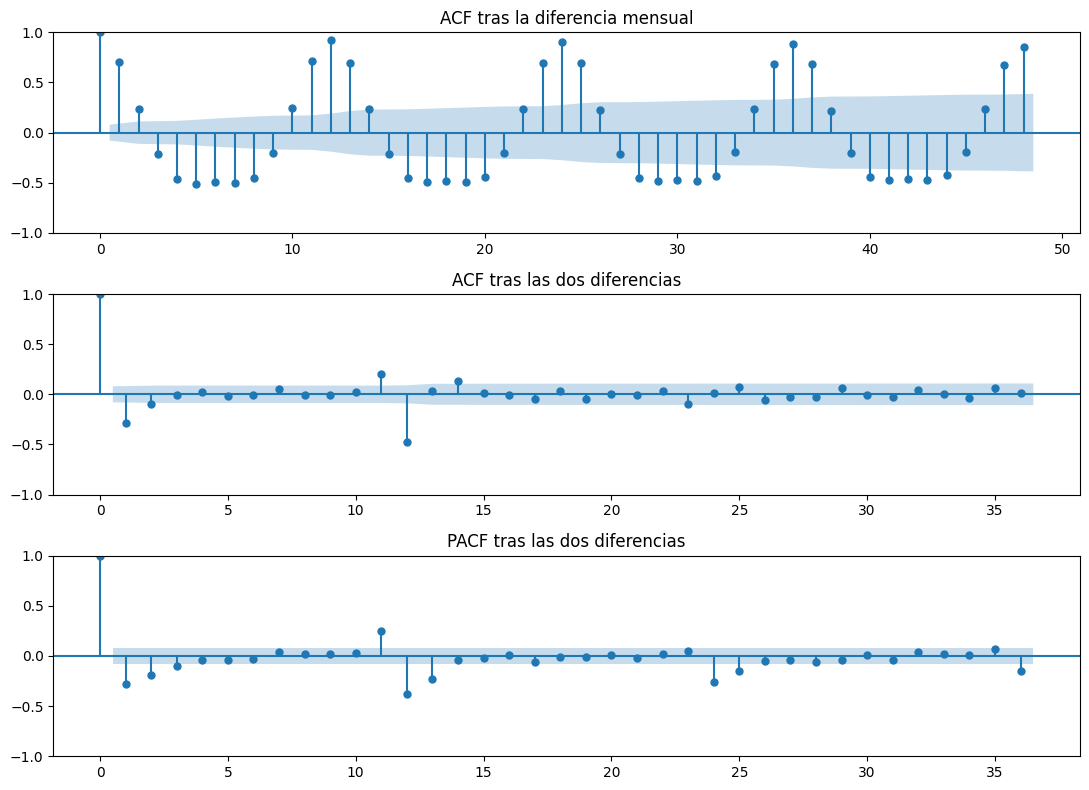

In [8]:
cambio_mensual = entrenamiento.diff().dropna()
serie_diferenciada = cambio_mensual.diff(12).dropna()
print(f"ADF inicial, con constante y tendencia: p = {adfuller(entrenamiento, regression='ct')[1]:.3g}")
print(f"ADF después de ambas diferencias: p = {adfuller(serie_diferenciada)[1]:.3g}")
fig, ejes = plt.subplots(3, 1, figsize=(11, 8))
plot_acf(cambio_mensual, lags=48, ax=ejes[0], title="ACF tras la diferencia mensual")
plot_acf(serie_diferenciada, lags=36, ax=ejes[1], title="ACF tras las dos diferencias")
plot_pacf(serie_diferenciada, lags=36, method="ywm", ax=ejes[2], title="PACF tras las dos diferencias")
fig.tight_layout()
plt.show()

In [9]:
candidatos = [
    ((0, 1, 1), (0, 1, 1, 12)),
    ((1, 1, 1), (0, 1, 1, 12)),
    ((0, 1, 2), (1, 1, 1, 12)),
    ((0, 1, 1), (1, 1, 1, 12)),
    ((1, 1, 0), (1, 1, 0, 12)),
]
ajustes = {}
filas = []
for orden, estacional in candidatos:
    nombre = f"{orden} × {estacional}"
    ajuste = SARIMAX(entrenamiento, order=orden, seasonal_order=estacional).fit(disp=False, maxiter=100)
    ajustes[nombre] = ajuste
    residuo = ajuste.resid.iloc[13:]
    p_ljung = acorr_ljungbox(residuo, lags=[24], model_df=len(ajuste.params) - 1, return_df=True)
    filas.append({
        "Modelo": nombre,
        "AIC": ajuste.aic,
        "BIC": ajuste.bic,
        "p Ljung–Box (24)": p_ljung["lb_pvalue"].iloc[0],
        "Convergió": ajuste.mle_retvals["converged"],
    })

tabla = pd.DataFrame(filas).set_index("Modelo").sort_values("BIC")
display(tabla.round(3))
elegibles = tabla.loc[tabla["Convergió"]]
if elegibles.empty:
    raise RuntimeError("Ningún candidato convergió.")
ganador = elegibles.index[0]
display(ajustes[ganador].summary().tables[1])

,AIC,BIC,p Ljung–Box (24),Convergió
Modelo,,,,
"(0, 1, 1) × (0, 1, 1, 12)",339.592,352.778,0.763,True
"(1, 1, 1) × (0, 1, 1, 12)",338.140,355.721,0.866,True
"(0, 1, 1) × (1, 1, 1, 12)",341.350,358.931,0.695,True
"(0, 1, 2) × (1, 1, 1, 12)",339.761,361.738,0.831,True
"(1, 1, 0) × (1, 1, 0, 12)",516.729,529.915,0.000,True


,coef,std err,z,P>|z|,[0.025,0.975]
ma.L1,-0.4103,0.035,-11.760,0.000,-0.479,-0.342
ma.S.L12,-0.8848,0.022,-39.709,0.000,-0.928,-0.841
sigma2,0.0991,0.005,19.569,0.000,0.089,0.109


Modelo por BIC (0, 1, 1) × (0, 1, 1, 12) · RMSE 0.64 ppm · MAE 0.57 ppm


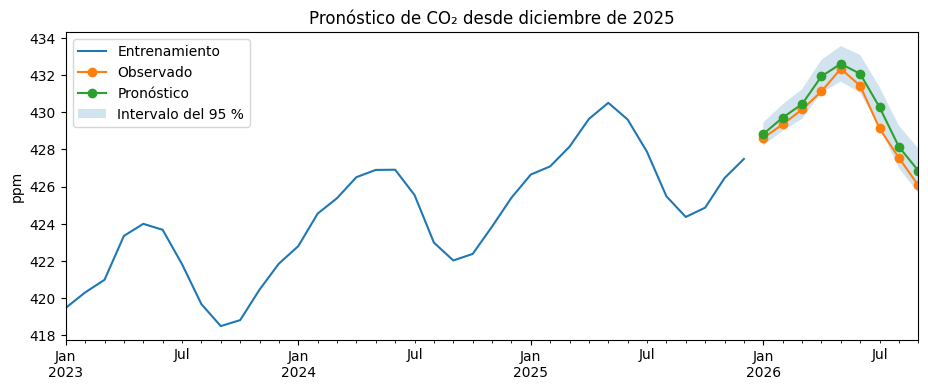

In [10]:
periodos = pd.date_range("2026-01-01", "2026-09-01", freq="MS")
pronostico = ajustes[ganador].get_forecast(steps=len(periodos)).summary_frame(alpha=.05)
evaluacion = pronostico.join(prueba.rename("Observado")).dropna(subset=["Observado"])
if len(evaluacion):
    rmse_ppm = np.sqrt(mean_squared_error(evaluacion["Observado"], evaluacion["mean"]))
    mae_ppm = mean_absolute_error(evaluacion["Observado"], evaluacion["mean"])
    print(f"Modelo por BIC {ganador} · RMSE {rmse_ppm:.2f} ppm · MAE {mae_ppm:.2f} ppm")

fig, eje = plt.subplots(figsize=(11, 4))
entrenamiento.iloc[-36:].plot(ax=eje, label="Entrenamiento")
prueba.plot(ax=eje, marker="o", label="Observado")
pronostico["mean"].plot(ax=eje, marker="o", label="Pronóstico")
eje.fill_between(pronostico.index, pronostico["mean_ci_lower"], pronostico["mean_ci_upper"],
                 alpha=.2, label="Intervalo del 95 %")
eje.set(title="Pronóstico de CO₂ desde diciembre de 2025", ylabel="ppm")
eje.legend()
plt.show()